# Denver Solar Microgrid — Spatiotemporal & Evening Advection Climate Graph
> **Tracks:** Veritas AI International High School Hackathon (**Climate Track**) · NASA Space Apps Challenge 2026 (**"Be An Earth System Trend Detective!"**)

**1 City:** Denver, CO (`39.74° N, -104.99° W`)  
**1 User:** Denver K-12 School / Community Microgrid Operator (`250 kWdc PV + 350 kWh LFP Battery`)  
**1 Decision:** At `23:00 MST`, predict whether tomorrow's daily solar irradiance (`ALLSKY_SFC_SW_DWN`) falls below **3.5 kWh/m²/day** and decide whether to pre-charge the backup battery overnight at off-peak rates (`$0.075/kWh`) to prevent expensive daytime storm shortfalls (`$0.280/kWh`).

### Architecture & Critical-Fractile Quantile Dispatch
- **7-Node Local Climate Graph:** Denver (Target) + 6 surrounding/upwind coordinates (`93–156 km` W, NNW, N, NE, E, S) capturing Continental Divide Pacific cloud decks, northern Front Range fronts, and eastern plains upslope moisture.
- **Multi-Source Observations (`2019-01-01` to `2026-11-09`):**
  1. **NASA POWER Daily API:** `ALLSKY_SFC_SW_DWN`, `CLRSKY_SFC_SW_DWN`, `T2M`, `RH2M`, `PRECTOTCORR`, `WS10M`, `WD10M`, `PS`.
  2. **Open-Meteo Archive Hourly (`18:00–23:00 America/Denver`):** evening cloud cover (`cloud_cover`), evening humidity (`relative_humidity_2m`), wind speed/direction (`wind_speed_10m`, `wind_direction_10m`), and 5-hour surface pressure tendency (`ps_23h - ps_18h`).
- **Zero-Tuning Newsvendor Decision Rule:** Under asymmetric Colorado TOU tariffs (`$0.075/kWh` off-peak pre-charge vs. `$0.280/kWh` on-peak shortfall), the Bayes-optimal lower-tail risk fractile is fixed a priori by the tariff ratio $q^* = p_{\\text{off}} / p_{\\text{peak}} = 0.075 / 0.280 \approx 0.268$: pre-charge overnight iff $Q_{0.268}(\\text{ALLSKY}_{t+1} \mid X_t) < 3.50\\text{ kWh/m}^2\\text{/d}$.
- **Strict Chronological Split (Zero Leakage):** Train = `2019–2023` (`1,824` days) | Validation = `2024` (`366` days) | Held-Out Unseen Test = `2025–2026` (`606` days).
- **4-Way Controlled Ablation:** `Persistence` vs. `Local-Only Daily` vs. `Local + 23:00 Evening` vs. `Graph + 23:00 Evening`.

### Credits, Prototype Scope & AI Disclosure
- **Datasets:** [NASA POWER Project](https://power.larc.nasa.gov/) (CERES SYN1deg & MERRA-2) · [Open-Meteo Historical Archive](https://open-meteo.com/) (ERA5 hourly).
- **Operational Prototype Disclaimer:** Tariff penalties (`$0.075/$0.280 per kWh`) model a representative Colorado commercial TOU schedule for research evaluation; live building dispatch requires site telemetry and utility interconnection.
- **AI Disclosure:** AI coding assistants (Google Gemini / Antigravity, Claude) assisted with notebook formatting and UI scaffolding; problem framing, upwind cosine graph design, evening sub-daily advection features, critical-fractile quantile dispatch, and failure analysis were author-designed and verified on live API data.

In [1]:
# Cell 1: Imports, 7-Node Front Range Graph Definition & Microgrid Cost Helpers
import math, time, requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, precision_recall_fscore_support

LOW_SOLAR_THRESHOLD = 3.5  # kWh/m^2/day physical storm shortfall threshold

# Denver K-12 School Microgrid Tariff & Storage Simulation
SCHOOL_PV_KW = 250.0
BATTERY_USABLE_KWH = 350.0
OFF_PEAK_USD_KWH = 0.075
ON_PEAK_USD_KWH = 0.280
FALSE_POSITIVE_COST_USD = BATTERY_USABLE_KWH * OFF_PEAK_USD_KWH        # $26.25
DEFICIT_SPREAD_USD_KWH = ON_PEAK_USD_KWH - OFF_PEAK_USD_KWH            # $0.205/kWh
CRITICAL_FRACTILE_Q = OFF_PEAK_USD_KWH / ON_PEAK_USD_KWH               # 0.2679 exact Newsvendor fractile

NODES = [
    {"id": "denver", "name": "Denver (Target)", "dir": "CENTER", "lat": 39.74, "lng": -104.99},
    {"id": "silverthorne", "name": "Silverthorne / Divide", "dir": "W", "lat": 39.63, "lng": -106.07},
    {"id": "fort_collins", "name": "Fort Collins", "dir": "NNW", "lat": 40.59, "lng": -105.08},
    {"id": "cheyenne", "name": "Cheyenne, WY", "dir": "N", "lat": 41.14, "lng": -104.82},
    {"id": "greeley", "name": "Greeley / Plains", "dir": "NE", "lat": 40.25, "lng": -104.05},
    {"id": "limon", "name": "Limon / E Plains", "dir": "E", "lat": 39.26, "lng": -103.69},
    {"id": "colo_springs", "name": "Colorado Springs", "dir": "S", "lat": 38.83, "lng": -104.82},
]

def bearing_deg(lat1, lng1, lat2, lng2):
    p1, p2 = math.radians(lat1), math.radians(lat2)
    dl = math.radians(lng2 - lng1)
    y = math.sin(dl) * math.cos(p2)
    x = math.cos(p1) * math.sin(p2) - math.sin(p1) * math.cos(p2) * math.cos(dl)
    return (math.degrees(math.atan2(y, x)) + 360.0) % 360.0

for n in NODES:
    n["bearing_from_denver"] = 0.0 if n["id"] == "denver" else bearing_deg(39.74, -104.99, n["lat"], n["lng"])

def daily_policy_costs(y_true, precharge_mask):
    costs = np.zeros(len(y_true), dtype=float)
    for i, (actual, precharge) in enumerate(zip(y_true, precharge_mask)):
        if actual < LOW_SOLAR_THRESHOLD:
            if not precharge:
                unbuffered = min(BATTERY_USABLE_KWH, max(0.0, (LOW_SOLAR_THRESHOLD - actual) * SCHOOL_PV_KW))
                costs[i] = unbuffered * DEFICIT_SPREAD_USD_KWH
        elif precharge:
            costs[i] = FALSE_POSITIVE_COST_USD
    return costs

def simulate_decisions_cost(y_true, precharge_mask):
    costs = daily_policy_costs(y_true, precharge_mask)
    y_arr = np.asarray(y_true)
    p_arr = np.asarray(precharge_mask, dtype=bool)
    low_mask = y_arr < LOW_SOLAR_THRESHOLD
    low_days = int(low_mask.sum())
    shortfall_days = int((low_mask & ~p_arr).sum())
    fp_days = int((~low_mask & p_arr).sum())
    ann_cost = float(costs.sum()) * (365.25 / max(1, len(y_arr)))
    storm_recall = ((low_days - shortfall_days) / low_days * 100.0) if low_days > 0 else 100.0
    return {
        "ann_cost": ann_cost,
        "storm_recall": storm_recall,
        "shortfall_days": shortfall_days,
        "low_days": low_days,
        "fp_days": fp_days,
        "daily_costs": costs,
    }

print(
    f"Configured {len(NODES)} Front Range nodes | Battery={BATTERY_USABLE_KWH:.0f} kWh | "
    f"PV={SCHOOL_PV_KW:.0f} kWdc | Newsvendor q*={CRITICAL_FRACTILE_Q:.3f}"
)

Configured 7 Front Range nodes | Battery=350 kWh | PV=250 kWdc | Newsvendor q*=0.268


In [2]:
# Cell 2: Fetch NASA POWER Daily + Open-Meteo Evening Hourly (18:00-23:00 America/Denver) across 7 Nodes
START_POWER, END_POWER = "20190101", "20261109"
START_OM, END_OM = "2019-01-01", "2026-11-09"
PARAMS = "ALLSKY_SFC_SW_DWN,CLRSKY_SFC_SW_DWN,T2M,RH2M,PRECTOTCORR,WS10M,WD10M,PS"

def fetch_nasa_power_daily(lat, lng, start=START_POWER, end=END_POWER):
    url = (
        f"https://power.larc.nasa.gov/api/temporal/daily/point"
        f"?parameters={PARAMS}&community=RE&longitude={lng}&latitude={lat}"
        f"&start={start}&end={end}&format=JSON"
    )
    for attempt in range(3):
        r = requests.get(url, timeout=30)
        if r.status_code == 200:
            p = r.json()["properties"]["parameter"]
            df = pd.DataFrame(p)
            df.index = pd.to_datetime(df.index, format="%Y%m%d")
            df = df.replace(-999.0, np.nan).sort_index()
            df["kt"] = df["ALLSKY_SFC_SW_DWN"] / df["CLRSKY_SFC_SW_DWN"].clip(lower=0.5)
            return df
        time.sleep(1.5 * (attempt + 1))
    r.raise_for_status()

def fetch_evening_hourly_all_nodes(nodes, start_iso=START_OM, end_iso=END_OM):
    lats = ",".join(str(n["lat"]) for n in nodes)
    lngs = ",".join(str(n["lng"]) for n in nodes)
    url = (
        f"https://archive-api.open-meteo.com/v1/archive?latitude={lats}&longitude={lngs}"
        f"&start_date={start_iso}&end_date={end_iso}"
        f"&hourly=cloud_cover,surface_pressure,relative_humidity_2m,wind_speed_10m,wind_direction_10m"
        f"&wind_speed_unit=ms&timezone=America%2FDenver"
    )
    for attempt in range(3):
        r = requests.get(url, timeout=60)
        if r.status_code == 200:
            payload = r.json()
            items = payload if isinstance(payload, list) else [payload]
            out = {}
            for n, item in zip(nodes, items):
                h = pd.DataFrame(item["hourly"])
                h["dt"] = pd.to_datetime(h["time"])
                h = h[(h["dt"].dt.hour >= 18) & (h["dt"].dt.hour <= 23)].copy()
                h["date"] = h["dt"].dt.normalize()
                g = h.groupby("date")
                eve_df = pd.DataFrame({
                    "eve_cloud_mean": g["cloud_cover"].mean(),
                    "eve_cloud_23": g["cloud_cover"].last(),
                    "eve_rh_mean": g["relative_humidity_2m"].mean(),
                    "eve_ws_mean": g["wind_speed_10m"].mean(),
                    "eve_wd_23": g["wind_direction_10m"].last(),
                    "eve_ps_trend": g["surface_pressure"].last() - g["surface_pressure"].first(),
                })
                out[n["id"]] = eve_df
            return out
        time.sleep(2.0 * (attempt + 1))
    r.raise_for_status()

eve_by_node = fetch_evening_hourly_all_nodes(NODES)
dfs = {}
for n in NODES:
    daily = fetch_nasa_power_daily(n["lat"], n["lng"]).join(eve_by_node[n["id"]], how="left")
    dfs[n["id"]] = daily
    print(f"Fetched {n['name']:24s}: {len(daily)} days | mean ALLSKY = {daily['ALLSKY_SFC_SW_DWN'].mean():.2f} | eve_23h_cov = {daily['eve_cloud_23'].notna().mean():.1%}")

Fetched Denver (Target)         : 2870 days | mean ALLSKY = 4.90 | eve_23h_cov = 100.0%


Fetched Silverthorne / Divide   : 2870 days | mean ALLSKY = 4.91 | eve_23h_cov = 100.0%


Fetched Fort Collins            : 2870 days | mean ALLSKY = 4.68 | eve_23h_cov = 100.0%


Fetched Cheyenne, WY            : 2870 days | mean ALLSKY = 4.64 | eve_23h_cov = 100.0%


Fetched Greeley / Plains        : 2870 days | mean ALLSKY = 4.78 | eve_23h_cov = 100.0%


Fetched Limon / E Plains        : 2870 days | mean ALLSKY = 4.97 | eve_23h_cov = 100.0%


Fetched Colorado Springs        : 2870 days | mean ALLSKY = 5.05 | eve_23h_cov = 100.0%


In [3]:
# Cell 3: Leak-Free Daily + Evening Advection Features & Chronological Train / Val / Unseen Test Splits
base = dfs["denver"].copy()
base["target_next_allsky"] = base["ALLSKY_SFC_SW_DWN"].shift(-1)
base["next_clrsky"] = base["CLRSKY_SFC_SW_DWN"].shift(-1)
base["doy_next"] = (base.index + pd.Timedelta(days=1)).day_of_year
base["sin_doy"] = np.sin(2 * np.pi * base["doy_next"] / 365.25)
base["cos_doy"] = np.cos(2 * np.pi * base["doy_next"] / 365.25)
base["kt_roll3"] = base["kt"].rolling(3).mean()
base["kt_lag1"] = base["kt"].shift(1)
base["wd_sin"] = np.sin(np.radians(base["WD10M"]))
base["wd_cos"] = np.cos(np.radians(base["WD10M"]))
base["eve_wd_sin"] = np.sin(np.radians(base["eve_wd_23"]))
base["eve_wd_cos"] = np.cos(np.radians(base["eve_wd_23"]))

local_daily_cols = [
    "ALLSKY_SFC_SW_DWN", "next_clrsky", "kt", "kt_roll3", "kt_lag1",
    "T2M", "RH2M", "PRECTOTCORR", "WS10M", "wd_sin", "wd_cos", "PS",
    "sin_doy", "cos_doy"
]

local_eve_cols = local_daily_cols + [
    "eve_cloud_mean", "eve_cloud_23", "eve_rh_mean", "eve_ws_mean",
    "eve_wd_sin", "eve_wd_cos", "eve_ps_trend"
]

neighbors = [n for n in NODES if n["id"] != "denver"]
upwind_kt_num = np.zeros(len(base))
upwind_kt_den = np.zeros(len(base))
upwind_precip_num = np.zeros(len(base))
upwind_eve_cloud_num = np.zeros(len(base))
upwind_eve_rh_num = np.zeros(len(base))
upwind_eve_den = np.zeros(len(base))
neighbor_graph_cols = []

for n in neighbors:
    nid = n["id"]
    ndf = dfs[nid].reindex(base.index)
    base[f"{nid}_kt"] = ndf["kt"]
    base[f"{nid}_dkt"] = ndf["kt"] - base["kt"]
    base[f"{nid}_eve_cloud23"] = ndf["eve_cloud_23"]
    neighbor_graph_cols.extend([f"{nid}_kt", f"{nid}_dkt", f"{nid}_eve_cloud23"])

    w_daily = np.maximum(0.0, np.cos(np.radians(base["WD10M"].values - n["bearing_from_denver"])))
    upwind_kt_num += w_daily * ndf["kt"].fillna(base["kt"]).values
    upwind_precip_num += w_daily * ndf["PRECTOTCORR"].fillna(0.0).values
    upwind_kt_den += w_daily

    w_eve = np.maximum(0.0, np.cos(np.radians(base["eve_wd_23"].values - n["bearing_from_denver"])))
    upwind_eve_cloud_num += w_eve * ndf["eve_cloud_23"].fillna(base["eve_cloud_23"]).values
    upwind_eve_rh_num += w_eve * ndf["eve_rh_mean"].fillna(base["eve_rh_mean"]).values
    upwind_eve_den += w_eve

base["upwind_kt"] = np.where(upwind_kt_den > 1e-4, upwind_kt_num / upwind_kt_den, base["kt"])
base["upwind_kt_x_clrsky"] = base["upwind_kt"] * base["next_clrsky"]
base["upwind_precip"] = np.where(upwind_kt_den > 1e-4, upwind_precip_num / upwind_kt_den, base["PRECTOTCORR"])
base["upwind_grad"] = base["upwind_kt"] - base["kt"]
base["upwind_eve_cloud"] = np.where(upwind_eve_den > 1e-4, upwind_eve_cloud_num / upwind_eve_den, base["eve_cloud_23"])
base["upwind_eve_rh"] = np.where(upwind_eve_den > 1e-4, upwind_eve_rh_num / upwind_eve_den, base["eve_rh_mean"])
base["upwind_eve_clear_x_clrsky"] = (1.0 - base["upwind_eve_cloud"] / 100.0) * base["next_clrsky"]
base["upslope_moisture_idx"] = np.maximum(0.0, base["eve_wd_sin"]) * (base["upwind_eve_rh"] / 100.0)

graph_eve_cols = local_eve_cols + [
    "upwind_kt", "upwind_kt_x_clrsky", "upwind_precip", "upwind_grad",
    "upwind_eve_cloud", "upwind_eve_rh", "upwind_eve_clear_x_clrsky", "upslope_moisture_idx"
] + neighbor_graph_cols

data = base.dropna(subset=graph_eve_cols + ["target_next_allsky"]).copy()
train = data[data.index < "2024-01-01"]
val   = data[(data.index >= "2024-01-01") & (data.index < "2025-01-01")]
test  = data[data.index >= "2025-01-01"]

print(f"Strict Temporal Split -> Train (2019-2023): {len(train)} | Val (2024): {len(val)} | Unseen Test (2025-2026): {len(test)} days")

Strict Temporal Split -> Train (2019-2023): 1824 | Val (2024): 366 | Unseen Test (2025-2026): 606 days


In [4]:
# Cell 4: 4-Way Controlled Ablation, Critical-Fractile Quantile Dispatch & Significance Tests
from sklearn.inspection import permutation_importance

def paired_diff_p(series_a, series_b):
    d = np.asarray(series_a) - np.asarray(series_b)
    se = d.std(ddof=1) / math.sqrt(len(d))
    z = abs(d.mean() / se) if se > 1e-12 else 0.0
    return math.erfc(z / math.sqrt(2.0))

def make_mean_hgbr():
    return HistGradientBoostingRegressor(max_depth=4, learning_rate=0.05, max_iter=200, random_state=42)

def make_quantile_hgbr(q=CRITICAL_FRACTILE_Q):
    return HistGradientBoostingRegressor(loss="quantile", quantile=q, max_depth=4, learning_rate=0.05, max_iter=200, random_state=42)

# Stage 1: Leak-free validation check on 2024 using fixed physical Newsvendor fractile q* = p_off / p_peak (zero free tuning)
y_val = val["target_next_allsky"].values
qval_ld = make_quantile_hgbr().fit(train[local_daily_cols], train["target_next_allsky"]).predict(val[local_daily_cols])
qval_le = make_quantile_hgbr().fit(train[local_eve_cols], train["target_next_allsky"]).predict(val[local_eve_cols])
qval_ge = make_quantile_hgbr().fit(train[graph_eve_cols], train["target_next_allsky"]).predict(val[graph_eve_cols])

print(
    f"2024 Validation Check (q*={CRITICAL_FRACTILE_Q:.3f}, cutoff={LOW_SOLAR_THRESHOLD:.2f}): "
    f"Local-Daily=${simulate_decisions_cost(y_val, qval_ld < LOW_SOLAR_THRESHOLD)['ann_cost']:.0f}/yr -> "
    f"Local+23h=${simulate_decisions_cost(y_val, qval_le < LOW_SOLAR_THRESHOLD)['ann_cost']:.0f}/yr -> "
    f"Graph+23h=${simulate_decisions_cost(y_val, qval_ge < LOW_SOLAR_THRESHOLD)['ann_cost']:.0f}/yr"
)

# Stage 2: Fit final models on Train+Val (2019-2024), freeze weights, evaluate once on Unseen 2025-2026
train_full = pd.concat([train, val])
y_test = test["target_next_allsky"].values
pred_persist = test["ALLSKY_SFC_SW_DWN"].values
dec_persist = pred_persist < LOW_SOLAR_THRESHOLD

m_ld = make_mean_hgbr().fit(train_full[local_daily_cols], train_full["target_next_allsky"])
m_le = make_mean_hgbr().fit(train_full[local_eve_cols], train_full["target_next_allsky"])
m_ge = make_mean_hgbr().fit(train_full[graph_eve_cols], train_full["target_next_allsky"])

pred_ld = np.clip(m_ld.predict(test[local_daily_cols]), 0, None)
pred_le = np.clip(m_le.predict(test[local_eve_cols]), 0, None)
pred_ge = np.clip(m_ge.predict(test[graph_eve_cols]), 0, None)

q_ld = np.clip(make_quantile_hgbr().fit(train_full[local_daily_cols], train_full["target_next_allsky"]).predict(test[local_daily_cols]), 0, None)
q_le = np.clip(make_quantile_hgbr().fit(train_full[local_eve_cols], train_full["target_next_allsky"]).predict(test[local_eve_cols]), 0, None)
q_ge = np.clip(make_quantile_hgbr().fit(train_full[graph_eve_cols], train_full["target_next_allsky"]).predict(test[graph_eve_cols]), 0, None)

dec_ld = q_ld < LOW_SOLAR_THRESHOLD
dec_le = q_le < LOW_SOLAR_THRESHOLD
dec_ge = q_ge < LOW_SOLAR_THRESHOLD

p_rmse = math.sqrt(mean_squared_error(y_test, pred_persist))
eco_persist = simulate_decisions_cost(y_test, dec_persist)
eco_le = simulate_decisions_cost(y_test, dec_le)
eco_ge = simulate_decisions_cost(y_test, dec_ge)
p_cost = eco_persist["ann_cost"]

def summarize(label, y_pred, decision_mask, policy_label):
    rmse = math.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    skill = (1.0 - rmse / p_rmse) * 100.0
    _, _, f1, _ = precision_recall_fscore_support(
        y_test < LOW_SOLAR_THRESHOLD, decision_mask, average="binary", zero_division=0
    )
    eco = simulate_decisions_cost(y_test, decision_mask)
    return {
        "Model": label,
        "RMSE": round(rmse, 4),
        "MAE": round(mae, 3),
        "R2": round(r2, 3),
        "Skill_%": round(skill, 1),
        "Dispatch_Rule": policy_label,
        "LowSolar_F1": round(f1, 3),
        "Storm_Recall_%": round(eco["storm_recall"], 1),
        "Cost_$/yr": round(eco["ann_cost"], 0),
        "Net_Save_$/yr": round(p_cost - eco["ann_cost"], 0),
    }

q_rule_lbl = f"Q{CRITICAL_FRACTILE_Q*100:.0f} < {LOW_SOLAR_THRESHOLD:.2f}"
results_df = pd.DataFrame([
    summarize("1. Persistence (Tomorrow=Today)", pred_persist, dec_persist, "Y_t < 3.50"),
    summarize("2. Local-Only Daily (HGBR)", pred_ld, dec_ld, q_rule_lbl),
    summarize("3. Local + 23:00 Eve (HGBR)", pred_le, dec_le, q_rule_lbl),
    summarize("4. Graph + 23:00 Eve (7-Node HGBR)", pred_ge, dec_ge, q_rule_lbl),
])
print()
print(results_df.to_string(index=False))

print(f"\nPaired Squared Error Significance (Unseen n={len(y_test)}):")
print(f"  Graph+Eve vs Persistence : p = {paired_diff_p((pred_persist - y_test) ** 2, (pred_ge - y_test) ** 2):.3e}")
print(f"  Graph+Eve vs Local-Daily : p = {paired_diff_p((pred_ld - y_test) ** 2, (pred_ge - y_test) ** 2):.3e}")
print(f"  Graph+Eve vs Local+Eve   : p = {paired_diff_p((pred_le - y_test) ** 2, (pred_ge - y_test) ** 2):.3e}")

print(f"\nPaired Daily Tariff Cost Significance (Unseen n={len(y_test)}):")
print(f"  Graph+Eve vs Persistence : p = {paired_diff_p(eco_persist['daily_costs'], eco_ge['daily_costs']):.3e}")
print(f"  Graph+Eve vs Local+Eve   : p = {paired_diff_p(eco_le['daily_costs'], eco_ge['daily_costs']):.3e}")

perm = permutation_importance(
    m_ge, test[graph_eve_cols], y_test, n_repeats=10, random_state=42, scoring="neg_root_mean_squared_error"
)
perm_df = pd.DataFrame({
    "Feature": graph_eve_cols,
    "Importance_Mean": np.round(perm.importances_mean, 4),
    "Importance_Std": np.round(perm.importances_std, 4),
}).sort_values("Importance_Mean", ascending=False).head(8)
print("\n=== TOP 8 PERMUTATION IMPORTANCES (Graph + 23:00 Evening HGBR) ===")
print(perm_df.to_string(index=False))

2024 Validation Check (q*=0.268, cutoff=3.50): Local-Daily=$1398/yr -> Local+23h=$1198/yr -> Graph+23h=$1133/yr



                             Model   RMSE   MAE    R2  Skill_% Dispatch_Rule  LowSolar_F1  Storm_Recall_%  Cost_$/yr  Net_Save_$/yr
   1. Persistence (Tomorrow=Today) 1.3819 0.988 0.539      0.0    Y_t < 3.50        0.766            76.6     1532.0            0.0
        2. Local-Only Daily (HGBR) 1.0232 0.789 0.747     26.0    Q27 < 3.50        0.773            82.6     1457.0           75.0
       3. Local + 23:00 Eve (HGBR) 0.9404 0.696 0.786     32.0    Q27 < 3.50        0.778            83.8     1433.0           99.0
4. Graph + 23:00 Eve (7-Node HGBR) 0.9278 0.686 0.792     32.9    Q27 < 3.50        0.813            88.6     1114.0          418.0

Paired Squared Error Significance (Unseen n=606):
  Graph+Eve vs Persistence : p = 4.963e-14
  Graph+Eve vs Local-Daily : p = 4.520e-04
  Graph+Eve vs Local+Eve   : p = 3.447e-01

Paired Daily Tariff Cost Significance (Unseen n=606):
  Graph+Eve vs Persistence : p = 2.275e-02
  Graph+Eve vs Local+Eve   : p = 1.351e-02



=== TOP 8 PERMUTATION IMPORTANCES (Graph + 23:00 Evening HGBR) ===
                  Feature  Importance_Mean  Importance_Std
              next_clrsky           1.0191          0.0407
                  cos_doy           0.0714          0.0106
       upwind_kt_x_clrsky           0.0323          0.0053
upwind_eve_clear_x_clrsky           0.0277          0.0068
 fort_collins_eve_cloud23           0.0256          0.0076
     cheyenne_eve_cloud23           0.0247          0.0064
              eve_rh_mean           0.0075          0.0035
                     RH2M           0.0069          0.0024


=== TOP 3 UNSEEN 2025-2026 FAILURES (Graph + 23:00 Evening) ===
Forecast Date: 2025-05-06 | Actual=1.41 | Graph+Eve=5.31 | LocalDaily=4.74 | Err=3.90 | 23hCloud=58%
Forecast Date: 2025-06-17 | Actual=2.98 | Graph+Eve=6.65 | LocalDaily=6.73 | Err=3.67 | 23hCloud=41%
Forecast Date: 2026-04-17 | Actual=2.55 | Graph+Eve=6.10 | LocalDaily=5.71 | Err=3.55 | 23hCloud=3%


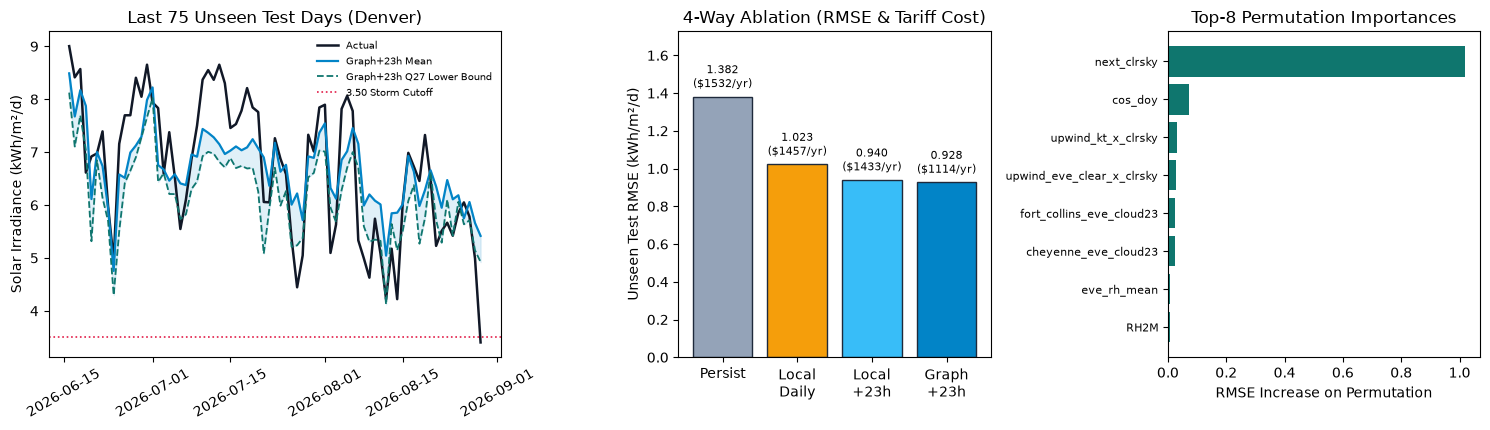

In [5]:
# Cell 5: Worst Unseen Failure Audit & Publication-Ready 3-Panel Visualization
test_out = test[["ALLSKY_SFC_SW_DWN", "target_next_allsky", "PRECTOTCORR", "WD10M", "WS10M", "eve_cloud_23", "upwind_eve_cloud"]].copy()
test_out["pred_persist"] = pred_persist
test_out["pred_local_daily"] = pred_ld
test_out["pred_graph_eve"] = pred_ge
test_out["q_graph_eve"] = q_ge
test_out["abs_err_graph"] = np.abs(test_out["pred_graph_eve"] - test_out["target_next_allsky"])

print("=== TOP 3 UNSEEN 2025-2026 FAILURES (Graph + 23:00 Evening) ===")
for dt, row in test_out.sort_values("abs_err_graph", ascending=False).head(3).iterrows():
    next_dt = (dt + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
    print(f"Forecast Date: {next_dt} | Actual={row['target_next_allsky']:.2f} | Graph+Eve={row['pred_graph_eve']:.2f} | LocalDaily={row['pred_local_daily']:.2f} | Err={row['abs_err_graph']:.2f} | 23hCloud={row['eve_cloud_23']:.0f}%")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1.45, 1.0, 1.0]})

recent = test_out.tail(75)
axes[0].plot(recent.index, recent["target_next_allsky"], label="Actual", color="#111827", lw=1.8)
axes[0].plot(recent.index, recent["pred_graph_eve"], label="Graph+23h Mean", color="#0284c7", lw=1.6)
axes[0].plot(recent.index, recent["q_graph_eve"], label="Graph+23h Q27 Lower Bound", color="#0f766e", ls="--", lw=1.3)
axes[0].fill_between(recent.index, recent["q_graph_eve"], recent["pred_graph_eve"], color="#0284c7", alpha=0.12)
axes[0].axhline(LOW_SOLAR_THRESHOLD, color="#e11d48", ls=":", lw=1.2, label="3.50 Storm Cutoff")
axes[0].set_title("Last 75 Unseen Test Days (Denver)")
axes[0].set_ylabel("Solar Irradiance (kWh/m²/d)")
axes[0].legend(fontsize=7.5, frameon=False)
axes[0].tick_params(axis="x", rotation=30)

labels_short = ["Persist", "Local\nDaily", "Local\n+23h", "Graph\n+23h"]
rmses = results_df["RMSE"].values
costs = results_df["Cost_$/yr"].values
bar_colors = ["#94a3b8", "#f59e0b", "#38bdf8", "#0284c7"]
axes[1].bar(labels_short, rmses, color=bar_colors, edgecolor="#1e293b")
for i, (r_val, c_val) in enumerate(zip(rmses, costs)):
    axes[1].text(i, r_val + 0.03, f"{r_val:.3f}\n(${c_val:.0f}/yr)", ha="center", va="bottom", fontsize=8)
axes[1].set_ylim(0, max(rmses) * 1.25)
axes[1].set_title("4-Way Ablation (RMSE & Tariff Cost)")
axes[1].set_ylabel("Unseen Test RMSE (kWh/m²/d)")

top_perm = perm_df.iloc[::-1]
axes[2].barh(top_perm["Feature"], top_perm["Importance_Mean"], color="#0f766e")
axes[2].set_title("Top-8 Permutation Importances")
axes[2].set_xlabel("RMSE Increase on Permutation")
axes[2].tick_params(axis="y", labelsize=8)

plt.tight_layout()
plt.show()